In [1]:

import pandas as pd
from pathlib import Path

# Project root
PROJECT_ROOT = Path.cwd().parent

print("Project root:", PROJECT_ROOT)

# Existing curated dataset directory
curated_dir = PROJECT_ROOT / "data" / "processed" / "curated"

# Load the four existing datasets
datasets = {
    "dishes": pd.read_csv(curated_dir / "dishes.csv"),
    "ingredients": pd.read_csv(curated_dir / "ingredients.csv"),
    "ingredient_reference": pd.read_csv(curated_dir / "ingredient_reference.csv"),
    "dish_nutrition": pd.read_csv(curated_dir / "dish_nutrition.csv")
}

# Confirm successful loading
for name, df in datasets.items():
    print(f"{name}: {df.shape}")


Project root: C:\Users\dell\NutriVision
dishes: (10, 3)
ingredients: (35, 3)
ingredient_reference: (9, 3)
dish_nutrition: (10, 8)


In [2]:

import pandas as pd
from pathlib import Path

# Project root
PROJECT_ROOT = Path.cwd().parent

# Output directory
text_dir = PROJECT_ROOT / "data" / "processed" / "text"
text_dir.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. Reference food descriptions
# --------------------------------------------------

food_descriptions = [
    {
        "dish_id": "DISH001",
        "description": "A rice dish containing chicken breast, white rice, grape tomatoes and yellow onions."
    },
    {
        "dish_id": "DISH002",
        "description": "A rice dish made with ground beef, white rice, grape tomatoes and yellow onions."
    },
    {
        "dish_id": "DISH003",
        "description": "A rice-based meal containing Atlantic salmon, white rice, grape tomatoes and yellow onions."
    },
    {
        "dish_id": "DISH004",
        "description": "A vegetable omelette containing whole eggs, grape tomatoes and yellow onions."
    },
    {
        "dish_id": "DISH005",
        "description": "A pasta dish combining chicken breast, spaghetti and grape tomatoes."
    },
    {
        "dish_id": "DISH006",
        "description": "Spaghetti served with ground beef and grape tomatoes."
    },
    {
        "dish_id": "DISH007",
        "description": "A potato-based dish containing russet potatoes, chicken breast and yellow onions."
    },
    {
        "dish_id": "DISH008",
        "description": "An egg-based dish combining whole eggs, tomatoes and yellow onions."
    },
    {
        "dish_id": "DISH009",
        "description": "A mixed bowl containing chicken breast, russet potatoes, grape tomatoes and yellow onions."
    },
    {
        "dish_id": "DISH010",
        "description": "A mixed bowl made with ground beef, russet potatoes, grape tomatoes and yellow onions."
    }
]

description_df = pd.DataFrame(food_descriptions)

# Add dish names and categories from the existing dataset
description_df = (
    datasets["dishes"][["dish_id", "dish_name", "category"]]
    .merge(description_df, on="dish_id", how="left")
)

# Add ingredient names from the existing ingredient reference
ingredient_names = {
    "ING001": "grape tomatoes",
    "ING002": "whole eggs",
    "ING003": "yellow onions",
    "ING004": "russet potatoes",
    "ING005": "white rice",
    "ING006": "ground beef",
    "ING007": "chicken breast",
    "ING008": "Atlantic salmon",
    "ING009": "spaghetti"
}

ingredient_details = datasets["ingredients"].copy()
ingredient_details["ingredient_name"] = (
    ingredient_details["ingredient_id"].map(ingredient_names)
)

ingredients_text = (
    ingredient_details.groupby("dish_id")["ingredient_name"]
    .apply(lambda x: ", ".join(x))
    .reset_index(name="ingredients_text")
)

description_df = description_df.merge(
    ingredients_text,
    on="dish_id",
    how="left"
)

description_df = description_df[
    ["dish_id", "dish_name", "category",
     "ingredients_text", "description"]
]

# --------------------------------------------------
# 2. Independent retrieval queries
# --------------------------------------------------

retrieval_queries = [
    ("Q001", "Chicken breast accompanied by white rice with tomato and onion.", "DISH001"),
    ("Q002", "A meal of rice with chicken, grape tomatoes and yellow onions.", "DISH001"),

    ("Q003", "Ground beef served alongside rice, tomatoes and onion.", "DISH002"),
    ("Q004", "White rice combined with minced beef and fresh tomatoes.", "DISH002"),

    ("Q005", "Atlantic fish with rice, grape tomatoes and yellow onion.", "DISH003"),
    ("Q006", "A salmon meal accompanied by white rice and vegetables.", "DISH003"),

    ("Q007", "An omelette prepared with eggs, tomatoes and onion.", "DISH004"),
    ("Q008", "Whole eggs combined with grape tomatoes and yellow onions.", "DISH004"),

    ("Q009", "Chicken breast with spaghetti and tomatoes.", "DISH005"),
    ("Q010", "A pasta meal containing chicken and grape tomatoes.", "DISH005"),

    ("Q011", "Spaghetti with minced beef and tomato.", "DISH006"),
    ("Q012", "A pasta meal combining ground meat and grape tomatoes.", "DISH006"),

    ("Q013", "Russet potatoes accompanied by chicken and onion.", "DISH007"),
    ("Q014", "A potato dish containing chicken breast and yellow onions.", "DISH007"),

    ("Q015", "Eggs with tomatoes and onions.", "DISH008"),
    ("Q016", "A dish combining whole eggs with a generous amount of tomatoes.", "DISH008"),

    ("Q017", "A bowl of chicken, potatoes, tomatoes and onions.", "DISH009"),
    ("Q018", "Chicken breast with russet potatoes and vegetables.", "DISH009"),

    ("Q019", "Ground beef with potatoes, tomatoes and onions.", "DISH010"),
    ("Q020", "A bowl containing minced beef and russet potatoes with vegetables.", "DISH010")
]

queries_df = pd.DataFrame(
    retrieval_queries,
    columns=["query_id", "query_text", "expected_dish_id"]
)

# --------------------------------------------------
# 3. Save datasets
# --------------------------------------------------

description_path = text_dir / "food_descriptions.csv"
queries_path = text_dir / "retrieval_queries.csv"

description_df.to_csv(description_path, index=False)
queries_df.to_csv(queries_path, index=False)

print("Datasets created successfully!")
print("Food descriptions:", description_path)
print("Retrieval queries:", queries_path)

print("\nReference dataset shape:", description_df.shape)
print("Query dataset shape:", queries_df.shape)

display(description_df)
display(queries_df)

Datasets created successfully!
Food descriptions: C:\Users\dell\NutriVision\data\processed\text\food_descriptions.csv
Retrieval queries: C:\Users\dell\NutriVision\data\processed\text\retrieval_queries.csv

Reference dataset shape: (10, 5)
Query dataset shape: (20, 3)


,dish_id,dish_name,category,ingredients_text,description
0,DISH001,Chicken with Rice,Rice-based,"chicken breast, white rice, grape tomatoes, ye...","A rice dish containing chicken breast, white r..."
1,DISH002,Beef with Rice,Rice-based,"ground beef, white rice, grape tomatoes, yello...","A rice dish made with ground beef, white rice,..."
2,DISH003,Salmon with Rice,Rice-based,"Atlantic salmon, white rice, grape tomatoes, y...","A rice-based meal containing Atlantic salmon, ..."
3,DISH004,Vegetable Omelette,Egg-based,"whole eggs, grape tomatoes, yellow onions","A vegetable omelette containing whole eggs, gr..."
4,DISH005,Chicken Pasta,Pasta,"chicken breast, spaghetti, grape tomatoes","A pasta dish combining chicken breast, spaghet..."
5,DISH006,Spaghetti with Ground Beef,Pasta,"ground beef, spaghetti, grape tomatoes",Spaghetti served with ground beef and grape to...
6,DISH007,Baked Potato with Chicken,Potato-based,"russet potatoes, chicken breast, yellow onions",A potato-based dish containing russet potatoes...
7,DISH008,Tomato and Egg Dish,Egg-based,"whole eggs, grape tomatoes, yellow onions","An egg-based dish combining whole eggs, tomato..."
8,DISH009,Chicken and Vegetable Bowl,Mixed,"chicken breast, russet potatoes, grape tomatoe...","A mixed bowl containing chicken breast, russet..."
9,DISH010,Beef and Potato Bowl,Mixed,"ground beef, russet potatoes, grape tomatoes, ...","A mixed bowl made with ground beef, russet pot..."


,query_id,query_text,expected_dish_id
0,Q001,Chicken breast accompanied by white rice with ...,DISH001
1,Q002,"A meal of rice with chicken, grape tomatoes an...",DISH001
2,Q003,"Ground beef served alongside rice, tomatoes an...",DISH002
3,Q004,White rice combined with minced beef and fresh...,DISH002
4,Q005,"Atlantic fish with rice, grape tomatoes and ye...",DISH003
5,Q006,A salmon meal accompanied by white rice and ve...,DISH003
6,Q007,"An omelette prepared with eggs, tomatoes and o...",DISH004
7,Q008,Whole eggs combined with grape tomatoes and ye...,DISH004
8,Q009,Chicken breast with spaghetti and tomatoes.,DISH005
9,Q010,A pasta meal containing chicken and grape toma...,DISH005


In [3]:
# --------------------------------------------------
# Step 2.0.3 - Validate textual datasets
# --------------------------------------------------

description_df = pd.read_csv(description_path)
queries_df = pd.read_csv(queries_path)

# 1. Check unique identifiers
assert description_df["dish_id"].is_unique, "Duplicate dish IDs!"
assert queries_df["query_id"].is_unique, "Duplicate query IDs!"

# 2. Check dish references
valid_dish_ids = set(datasets["dishes"]["dish_id"])

assert set(description_df["dish_id"]) == valid_dish_ids, \
    "Reference descriptions do not match the original dishes!"

assert set(queries_df["expected_dish_id"]).issubset(valid_dish_ids), \
    "Some queries reference unknown dishes!"

# 3. Check missing and empty text
assert description_df["description"].notna().all()
assert description_df["ingredients_text"].notna().all()
assert queries_df["query_text"].notna().all()

assert description_df["description"].str.strip().ne("").all()
assert queries_df["query_text"].str.strip().ne("").all()

# 4. Check ingredient references
ingredient_ids = set(datasets["ingredient_reference"]["ingredient_id"])
used_ingredient_ids = set(datasets["ingredients"]["ingredient_id"])

assert used_ingredient_ids.issubset(ingredient_ids), \
    "Some ingredients have no reference!"

# 5. Check every dish has ingredients
ingredient_counts = datasets["ingredients"].groupby("dish_id").size()

assert set(ingredient_counts.index) == valid_dish_ids, \
    "Some dishes have no ingredients!"

# 6. Check query distribution
query_counts = queries_df.groupby("expected_dish_id").size()

assert (query_counts == 2).all(), \
    "Each dish should have exactly two test queries!"

assert len(query_counts) == len(valid_dish_ids)

# 7. Check duplicate text
assert not description_df["description"].duplicated().any()
assert not queries_df["query_text"].duplicated().any()

# 8. Display validation results
print("=" * 55)
print("TEXT DATASET VALIDATION")
print("=" * 55)

print("Reference dishes:", len(description_df))
print("Retrieval queries:", len(queries_df))
print("Unique dish IDs:", description_df["dish_id"].nunique())
print("Unique query IDs:", queries_df["query_id"].nunique())
print("Missing descriptions:", description_df["description"].isna().sum())
print("Missing ingredient lists:", description_df["ingredients_text"].isna().sum())
print("Missing queries:", queries_df["query_text"].isna().sum())
print("Invalid expected dish IDs:",
      (~queries_df["expected_dish_id"].isin(valid_dish_ids)).sum())

print("\nQueries per expected dish:")
display(query_counts.rename("query_count").to_frame())

print("\nAll validation checks passed!")

TEXT DATASET VALIDATION
Reference dishes: 10
Retrieval queries: 20
Unique dish IDs: 10
Unique query IDs: 20
Missing descriptions: 0
Missing ingredient lists: 0
Missing queries: 0
Invalid expected dish IDs: 0

Queries per expected dish:


,query_count
expected_dish_id,
DISH001,2
DISH002,2
DISH003,2
DISH004,2
DISH005,2
DISH006,2
DISH007,2
DISH008,2
DISH009,2



All validation checks passed!


## 2.1 Text Preprocessing

This section prepares the reference food descriptions and retrieval queries
for classical NLP processing.

The objective is to normalize textual data, handle punctuation and special
characters, tokenize text, examine stop words, and apply lemmatization
where appropriate.

In [4]:
# --------------------------------------------------
# Step 2.1.1 - Check NLP library availability
# --------------------------------------------------

import importlib.util

libraries = {
    "NLTK": "nltk",
    "spaCy": "spacy",
    "Scikit-learn": "sklearn"
}

for library_name, module_name in libraries.items():
    available = importlib.util.find_spec(module_name) is not None
    print(f"{library_name}: {'Available' if available else 'Not installed'}")

# Load the text datasets
description_df = pd.read_csv(description_path)
queries_df = pd.read_csv(queries_path)

print("\nReference descriptions:", len(description_df))
print("Retrieval queries:", len(queries_df))

print("\nExample reference description:")
print(description_df.loc[0, "description"])

print("\nExample retrieval query:")
print(queries_df.loc[0, "query_text"])

NLTK: Available
spaCy: Not installed
Scikit-learn: Available

Reference descriptions: 10
Retrieval queries: 20

Example reference description:
A rice dish containing chicken breast, white rice, grape tomatoes and yellow onions.

Example retrieval query:
Chicken breast accompanied by white rice with tomato and onion.


### 2.1.2 Text Normalization and Cleaning

The text is normalized to ensure consistent comparison between reference
descriptions and retrieval queries.

The following operations are applied:
- Conversion to lowercase.
- Replacement of punctuation and special characters with spaces.
- Removal of unnecessary whitespace.

Stop-word removal and lemmatization are considered separately to avoid
removing or altering meaningful food-related vocabulary.

In [5]:
# --------------------------------------------------
# Step 2.1.2 - Text normalization and cleaning
# --------------------------------------------------

import re

def clean_text(text):
    """
    Normalize and clean English food-related text.
    """
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Replace punctuation and special characters with spaces
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply cleaning to reference descriptions
description_df["clean_description"] = (
    description_df["description"].apply(clean_text)
)

# Apply cleaning to retrieval queries
queries_df["clean_query"] = (
    queries_df["query_text"].apply(clean_text)
)

# Display representative examples
print("REFERENCE DESCRIPTION")
print("Original:", description_df.loc[0, "description"])
print("Cleaned: ", description_df.loc[0, "clean_description"])

print("\nRETRIEVAL QUERY")
print("Original:", queries_df.loc[0, "query_text"])
print("Cleaned: ", queries_df.loc[0, "clean_query"])

REFERENCE DESCRIPTION
Original: A rice dish containing chicken breast, white rice, grape tomatoes and yellow onions.
Cleaned:  a rice dish containing chicken breast white rice grape tomatoes and yellow onions

RETRIEVAL QUERY
Original: Chicken breast accompanied by white rice with tomato and onion.
Cleaned:  chicken breast accompanied by white rice with tomato and onion


In [6]:
print("Description columns:")
print(description_df.columns.tolist())

print("\nQuery columns:")
print(queries_df.columns.tolist())

Description columns:
['dish_id', 'dish_name', 'category', 'ingredients_text', 'description', 'clean_description']

Query columns:
['query_id', 'query_text', 'expected_dish_id', 'clean_query']


In [7]:
# --------------------------------------------------
# Step 2.1.3 - Tokenization
# --------------------------------------------------

def tokenize_text(text):
    """
    Split cleaned text into individual tokens.
    """
    return text.split()


# Tokenize reference descriptions
description_df["tokens"] = (
    description_df["clean_description"].apply(tokenize_text)
)

# Tokenize retrieval queries
queries_df["tokens"] = (
    queries_df["clean_query"].apply(tokenize_text)
)

# Display representative examples
print("REFERENCE DESCRIPTION")
print(description_df.loc[0, "tokens"])

print("\nRETRIEVAL QUERY")
print(queries_df.loc[0, "tokens"])

REFERENCE DESCRIPTION
['a', 'rice', 'dish', 'containing', 'chicken', 'breast', 'white', 'rice', 'grape', 'tomatoes', 'and', 'yellow', 'onions']

RETRIEVAL QUERY
['chicken', 'breast', 'accompanied', 'by', 'white', 'rice', 'with', 'tomato', 'and', 'onion']


### 2.1.4 Stop-word Analysis

Stop words are common words that may contribute little to distinguishing
food descriptions.

Their occurrence is examined before deciding whether to remove them.
Food-related terms and meaningful descriptive vocabulary must be preserved.

In [8]:
# --------------------------------------------------
# Step 2.1.4 - Stop-word analysis
# --------------------------------------------------

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Combine tokens from both datasets
all_tokens = (
    description_df["tokens"].tolist()
    + queries_df["tokens"].tolist()
)

# Flatten token lists
all_tokens = [
    token
    for sentence in all_tokens
    for token in sentence
]

# Identify stop words present in the datasets
present_stop_words = sorted(
    set(all_tokens).intersection(ENGLISH_STOP_WORDS)
)

print("Stop words found in our datasets:")
print(present_stop_words)

print("\nNumber of stop words found:", len(present_stop_words))

Stop words found in our datasets:
['a', 'amount', 'an', 'and', 'by', 'made', 'of', 'whole', 'with']

Number of stop words found: 9


In [9]:
# Compare tokenization before and after stop-word removal

example_tokens = description_df.loc[0, "tokens"]

filtered_tokens = [
    token for token in example_tokens
    if token not in ENGLISH_STOP_WORDS
]

print("Original tokens:")
print(example_tokens)

print("\nTokens after stop-word removal:")
print(filtered_tokens)

Original tokens:
['a', 'rice', 'dish', 'containing', 'chicken', 'breast', 'white', 'rice', 'grape', 'tomatoes', 'and', 'yellow', 'onions']

Tokens after stop-word removal:
['rice', 'dish', 'containing', 'chicken', 'breast', 'white', 'rice', 'grape', 'tomatoes', 'yellow', 'onions']


In [10]:
# --------------------------------------------------
# Step 2.1.4 - Selective stop-word removal
# --------------------------------------------------

custom_stop_words = {
    "a",
    "an",
    "and",
    "by",
    "of",
    "with"
}

def remove_stop_words(tokens):
    """
    Remove selected grammatical stop words while
    preserving meaningful food-related vocabulary.
    """
    return [
        token for token in tokens
        if token not in custom_stop_words
    ]


# Apply to reference descriptions
description_df["filtered_tokens"] = (
    description_df["tokens"].apply(remove_stop_words)
)

# Apply to retrieval queries
queries_df["filtered_tokens"] = (
    queries_df["tokens"].apply(remove_stop_words)
)

print("Original tokens:")
print(description_df.loc[0, "tokens"])

print("\nTokens after selective stop-word removal:")
print(description_df.loc[0, "filtered_tokens"])

print("\nQuery tokens after selective stop-word removal:")
print(queries_df.loc[0, "filtered_tokens"])

Original tokens:
['a', 'rice', 'dish', 'containing', 'chicken', 'breast', 'white', 'rice', 'grape', 'tomatoes', 'and', 'yellow', 'onions']

Tokens after selective stop-word removal:
['rice', 'dish', 'containing', 'chicken', 'breast', 'white', 'rice', 'grape', 'tomatoes', 'yellow', 'onions']

Query tokens after selective stop-word removal:
['chicken', 'breast', 'accompanied', 'white', 'rice', 'tomato', 'onion']


In [11]:
# --------------------------------------------------
# Step 2.1.5 - Install NLTK
# --------------------------------------------------

import sys

!{sys.executable} -m pip install nltk

In [12]:
import nltk

nltk.download("wordnet")

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\dell\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [13]:
# --------------------------------------------------
# Step 2.1.5 - Test WordNet lemmatization
# --------------------------------------------------

from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

test_words = [
    "tomatoes",
    "onions",
    "potatoes",
    "eggs",
    "dishes",
    "chicken",
    "rice"
]

for word in test_words:
    print(f"{word:12} -> {lemmatizer.lemmatize(word, pos='n')}")

tomatoes     -> tomato
onions       -> onion
potatoes     -> potato
eggs         -> egg
dishes       -> dish
chicken      -> chicken
rice         -> rice


In [14]:
# --------------------------------------------------
# Step 2.1.5 - Apply lemmatization
# --------------------------------------------------

def lemmatize_tokens(tokens):
    """
    Apply English noun lemmatization to a token list.
    """
    return [
        lemmatizer.lemmatize(token, pos="n")
        for token in tokens
    ]


# Apply to reference descriptions
description_df["lemmatized_tokens"] = (
    description_df["filtered_tokens"].apply(lemmatize_tokens)
)

# Apply to retrieval queries
queries_df["lemmatized_tokens"] = (
    queries_df["filtered_tokens"].apply(lemmatize_tokens)
)


# Display representative examples
print("REFERENCE DESCRIPTION")
print("Before:", description_df.loc[0, "filtered_tokens"])
print("After: ", description_df.loc[0, "lemmatized_tokens"])

print("\nRETRIEVAL QUERY")
print("Before:", queries_df.loc[0, "filtered_tokens"])
print("After: ", queries_df.loc[0, "lemmatized_tokens"])

REFERENCE DESCRIPTION
Before: ['rice', 'dish', 'containing', 'chicken', 'breast', 'white', 'rice', 'grape', 'tomatoes', 'yellow', 'onions']
After:  ['rice', 'dish', 'containing', 'chicken', 'breast', 'white', 'rice', 'grape', 'tomato', 'yellow', 'onion']

RETRIEVAL QUERY
Before: ['chicken', 'breast', 'accompanied', 'white', 'rice', 'tomato', 'onion']
After:  ['chicken', 'breast', 'accompanied', 'white', 'rice', 'tomato', 'onion']


In [15]:
# --------------------------------------------------
# Step 2.1.6 - Final preprocessing comparison
# --------------------------------------------------

for i in range(3):
    print("=" * 65)

    print("DISH:", description_df.loc[i, "dish_name"])

    print("\nOriginal:")
    print(description_df.loc[i, "description"])

    print("\nCleaned:")
    print(description_df.loc[i, "clean_description"])

    print("\nFinal preprocessed text:")
    print(" ".join(description_df.loc[i, "lemmatized_tokens"]))


print("\n\nRETRIEVAL QUERY EXAMPLE")
print("=" * 65)

print("Original:")
print(queries_df.loc[0, "query_text"])

print("\nFinal preprocessed text:")
print(" ".join(queries_df.loc[0, "lemmatized_tokens"]))

DISH: Chicken with Rice

Original:
A rice dish containing chicken breast, white rice, grape tomatoes and yellow onions.

Cleaned:
a rice dish containing chicken breast white rice grape tomatoes and yellow onions

Final preprocessed text:
rice dish containing chicken breast white rice grape tomato yellow onion
DISH: Beef with Rice

Original:
A rice dish made with ground beef, white rice, grape tomatoes and yellow onions.

Cleaned:
a rice dish made with ground beef white rice grape tomatoes and yellow onions

Final preprocessed text:
rice dish made ground beef white rice grape tomato yellow onion
DISH: Salmon with Rice

Original:
A rice-based meal containing Atlantic salmon, white rice, grape tomatoes and yellow onions.

Cleaned:
a rice based meal containing atlantic salmon white rice grape tomatoes and yellow onions

Final preprocessed text:
rice based meal containing atlantic salmon white rice grape tomato yellow onion


RETRIEVAL QUERY EXAMPLE
Original:
Chicken breast accompanied by w

In [16]:
# --------------------------------------------------
# Step 2.1.7 - Inspect food vocabulary variations
# --------------------------------------------------

reference_vocabulary = {
    token
    for tokens in description_df["lemmatized_tokens"]
    for token in tokens
}

query_vocabulary = {
    token
    for tokens in queries_df["lemmatized_tokens"]
    for token in tokens
}

print("Reference vocabulary:")
print(sorted(reference_vocabulary))

print("\nQuery vocabulary:")
print(sorted(query_vocabulary))

print("\nQuery terms not present in reference vocabulary:")
print(sorted(query_vocabulary - reference_vocabulary))

Reference vocabulary:
['atlantic', 'based', 'beef', 'bowl', 'breast', 'chicken', 'combining', 'containing', 'dish', 'egg', 'grape', 'ground', 'made', 'meal', 'mixed', 'omelette', 'onion', 'pasta', 'potato', 'rice', 'russet', 'salmon', 'served', 'spaghetti', 'tomato', 'vegetable', 'white', 'whole', 'yellow']

Query vocabulary:
['accompanied', 'alongside', 'amount', 'atlantic', 'beef', 'bowl', 'breast', 'chicken', 'combined', 'combining', 'containing', 'dish', 'egg', 'fish', 'fresh', 'generous', 'grape', 'ground', 'meal', 'meat', 'minced', 'omelette', 'onion', 'pasta', 'potato', 'prepared', 'rice', 'russet', 'salmon', 'served', 'spaghetti', 'tomato', 'vegetable', 'white', 'whole', 'yellow']

Query terms not present in reference vocabulary:
['accompanied', 'alongside', 'amount', 'combined', 'fish', 'fresh', 'generous', 'meat', 'minced', 'prepared']


In [17]:
# --------------------------------------------------
# Step 2.1.8 - Final preprocessing validation
# --------------------------------------------------

# Check that all documents have tokens
assert description_df["lemmatized_tokens"].notna().all()
assert queries_df["lemmatized_tokens"].notna().all()

# Check that no document has an empty token list
assert description_df["lemmatized_tokens"].apply(len).gt(0).all()
assert queries_df["lemmatized_tokens"].apply(len).gt(0).all()

# Check that stop words were removed
for tokens in description_df["lemmatized_tokens"]:
    assert not set(tokens).intersection(custom_stop_words)

for tokens in queries_df["lemmatized_tokens"]:
    assert not set(tokens).intersection(custom_stop_words)

# Check that all tokens are lowercase
for tokens in description_df["lemmatized_tokens"]:
    assert all(token == token.lower() for token in tokens)

for tokens in queries_df["lemmatized_tokens"]:
    assert all(token == token.lower() for token in tokens)

# Calculate statistics
reference_token_count = sum(
    len(tokens) for tokens in description_df["lemmatized_tokens"]
)

query_token_count = sum(
    len(tokens) for tokens in queries_df["lemmatized_tokens"]
)

print("=" * 55)
print("FINAL PREPROCESSING VALIDATION")
print("=" * 55)

print("Processed reference descriptions:", len(description_df))
print("Processed retrieval queries:", len(queries_df))
print("Total reference tokens:", reference_token_count)
print("Total query tokens:", query_token_count)

print("\nAll preprocessing validation checks passed!")

FINAL PREPROCESSING VALIDATION
Processed reference descriptions: 10
Processed retrieval queries: 20
Total reference tokens: 98
Total query tokens: 118

All preprocessing validation checks passed!


### 2.1.9 Spelling Variation and Verb Normalization

The vocabulary inspection (2.1.7) revealed query terms absent from the
reference vocabulary. Two of these are handled at the preprocessing level:

- **Verb inflections** (combined/combining, served, prepared, made, containing)
  were not merged because lemmatization used noun mode only. A second
  lemmatization pass with verb mode is added. "ground" is protected, since
  WordNet would turn it into "grind" (the verb), which would corrupt the
  food term "ground beef".
- **Lexical variation** ("minced" vs "ground" for beef) is resolved with a small
  variation dictionary.

A few filler words ("accompanied", "alongside", "generous", "amount") carry no
information for distinguishing dishes and are removed.

Semantic relations such as fish -> salmon or meat -> beef are NOT handled here:
they are not spelling variants, and are left as a known limitation of
count-based representations (to be compared with embeddings in 2.2).

In [18]:
# --------------------------------------------------
# Step 2.1.9 - Spelling variation and verb normalization
# --------------------------------------------------

# 1. Lexical variation map (applied BEFORE lemmatization)
variation_map = {
    "minced": "ground",
}

# 2. Words that must not be verb-lemmatized (food terms)
protected_words = {"ground"}   # WordNet verb lemma of "ground" is "grind"

# 3. Filler words with no discriminative value (after lemmatization)
filler_words = {"accompany", "alongside", "generous", "amount"}


def normalize_variations(tokens):
    return [variation_map.get(token, token) for token in tokens]


def lemmatize_verbs(tokens):
    return [
        token if token in protected_words
        else lemmatizer.lemmatize(token, pos="v")
        for token in tokens
    ]


def remove_fillers(tokens):
    return [token for token in tokens if token not in filler_words]


def final_pipeline(tokens):
    """
    Starting from stop-word-filtered tokens:
    variation map -> noun lemma -> verb lemma -> filler removal
    """
    tokens = normalize_variations(tokens)
    tokens = lemmatize_tokens(tokens)    # noun lemmatization (2.1.5)
    tokens = lemmatize_verbs(tokens)
    tokens = remove_fillers(tokens)
    return tokens


description_df["final_tokens"] = description_df["filtered_tokens"].apply(final_pipeline)
queries_df["final_tokens"] = queries_df["filtered_tokens"].apply(final_pipeline)

# Joined strings (convenient for TfidfVectorizer / CountVectorizer in 2.2)
description_df["final_text"] = description_df["final_tokens"].apply(" ".join)
queries_df["final_text"] = queries_df["final_tokens"].apply(" ".join)

# --- Effect on representative examples ---
print("REFERENCE (DISH003)")
print("Before:", description_df.loc[2, "lemmatized_tokens"])
print("After: ", description_df.loc[2, "final_tokens"])

for i in [0, 3, 10]:
    print(f"\nQUERY {queries_df.loc[i, 'query_id']}")
    print("Original:", queries_df.loc[i, "query_text"])
    print("Before:  ", queries_df.loc[i, "lemmatized_tokens"])
    print("After:   ", queries_df.loc[i, "final_tokens"])

# --- Vocabulary mismatch: before vs after ---
ref_vocab = {t for toks in description_df["final_tokens"] for t in toks}
qry_vocab = {t for toks in queries_df["final_tokens"] for t in toks}

old_ref = {t for toks in description_df["lemmatized_tokens"] for t in toks}
old_qry = {t for toks in queries_df["lemmatized_tokens"] for t in toks}

print("\nQuery terms missing from reference vocabulary")
print("Before:", sorted(old_qry - old_ref))
print("After: ", sorted(qry_vocab - ref_vocab))
print(f"\nUnmatched query terms: {len(old_qry - old_ref)} -> {len(qry_vocab - ref_vocab)}")

REFERENCE (DISH003)
Before: ['rice', 'based', 'meal', 'containing', 'atlantic', 'salmon', 'white', 'rice', 'grape', 'tomato', 'yellow', 'onion']
After:  ['rice', 'base', 'meal', 'contain', 'atlantic', 'salmon', 'white', 'rice', 'grape', 'tomato', 'yellow', 'onion']

QUERY Q001
Original: Chicken breast accompanied by white rice with tomato and onion.
Before:   ['chicken', 'breast', 'accompanied', 'white', 'rice', 'tomato', 'onion']
After:    ['chicken', 'breast', 'white', 'rice', 'tomato', 'onion']

QUERY Q004
Original: White rice combined with minced beef and fresh tomatoes.
Before:   ['white', 'rice', 'combined', 'minced', 'beef', 'fresh', 'tomato']
After:    ['white', 'rice', 'combine', 'ground', 'beef', 'fresh', 'tomato']

QUERY Q011
Original: Spaghetti with minced beef and tomato.
Before:   ['spaghetti', 'minced', 'beef', 'tomato']
After:    ['spaghetti', 'ground', 'beef', 'tomato']

Query terms missing from reference vocabulary
Before: ['accompanied', 'alongside', 'amount', 'combi

In [19]:
# --------------------------------------------------
# Step 2.1.10 - Final preprocessing validation
# --------------------------------------------------

assert description_df["final_tokens"].apply(len).gt(0).all()
assert queries_df["final_tokens"].apply(len).gt(0).all()

# Protected term preserved, variants merged
all_final = {t for toks in description_df["final_tokens"] for t in toks} | \
            {t for toks in queries_df["final_tokens"] for t in toks}

assert "ground" in all_final and "grind" not in all_final
assert "minced" not in all_final
assert not (all_final & filler_words)

print("Reference tokens:", sum(len(t) for t in description_df["final_tokens"]))
print("Query tokens:    ", sum(len(t) for t in queries_df["final_tokens"]))
print("Final vocabulary size:", len(all_final))
print("\nPreprocessing pipeline complete. Use 'final_text' / 'final_tokens' for 2.2.")

Reference tokens: 98
Query tokens:     112
Final vocabulary size: 33

Preprocessing pipeline complete. Use 'final_text' / 'final_tokens' for 2.2.


In [20]:
# --------------------------------------------------
# Step 2.2.0 - Setup
# --------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

ref_texts = description_df["final_text"].tolist()
qry_texts = queries_df["final_text"].tolist()
dish_labels = description_df["dish_id"].tolist()

print("Reference documents:", len(ref_texts))
print("Queries:", len(qry_texts))
print("Example reference:", ref_texts[0])
print("Example query:    ", qry_texts[0])

Reference documents: 10
Queries: 20
Example reference: rice dish contain chicken breast white rice grape tomato yellow onion
Example query:     chicken breast white rice tomato onion


## 2.2 Text Representation

All representations are fitted on the 10 reference descriptions only and then
applied to the queries (no information from queries leaks into the vocabulary).

### 2.2.1 Bag of Words (BoW)

**Captures:** which words occur and how many times. Simple, fast, interpretable.

**Fails to capture:**
- *Word order:* "chicken with rice" and "rice with chicken" give identical vectors.
- *Context:* "ground" in "ground beef" is just another count.
- *Meaning:* "fish" and "salmon" are two unrelated columns.
- *Importance:* common words such as "rice" and "tomato" count as much as "salmon".

In [21]:
# --------------------------------------------------
# Step 2.2.1 - Bag of Words
# --------------------------------------------------
bow = CountVectorizer()
X_ref_bow = bow.fit_transform(ref_texts)
X_qry_bow = bow.transform(qry_texts)

print("Vocabulary size:", len(bow.get_feature_names_out()))
print("Reference matrix shape:", X_ref_bow.shape)
print("Query matrix shape:    ", X_qry_bow.shape)
print(f"Reference sparsity: {1 - X_ref_bow.nnz / np.prod(X_ref_bow.shape):.1%}")

bow_df = pd.DataFrame(
    X_ref_bow.toarray(),
    index=dish_labels,
    columns=bow.get_feature_names_out()
)
display(bow_df)

# Word order is lost: same words, different order -> identical vector
a = bow.transform(["chicken rice tomato"]).toarray()
b = bow.transform(["tomato rice chicken"]).toarray()
print("\nWord-order test: identical vectors?", np.array_equal(a, b))

# Words unseen at fit time are silently dropped
q = queries_df.loc[queries_df["final_text"].str.contains("fish"), "final_text"].iloc[0]
print("\nQuery with out-of-vocabulary word:", q)
print("Non-zero BoW entries:", [bow.get_feature_names_out()[i] for i in bow.transform([q]).nonzero()[1]])

Vocabulary size: 29
Reference matrix shape: (10, 29)
Query matrix shape:     (20, 29)
Reference sparsity: 67.9%


,atlantic,base,beef,bowl,breast,chicken,combine,contain,dish,egg,...,rice,russet,salmon,serve,spaghetti,tomato,vegetable,white,whole,yellow
DISH001,0,0,0,0,1,1,0,1,1,0,...,2,0,0,0,0,1,0,1,0,1
DISH002,0,0,1,0,0,0,0,0,1,0,...,2,0,0,0,0,1,0,1,0,1
DISH003,1,1,0,0,0,0,0,1,0,0,...,2,0,1,0,0,1,0,1,0,1
DISH004,0,0,0,0,0,0,0,1,0,1,...,0,0,0,0,0,1,1,0,1,1
DISH005,0,0,0,0,1,1,1,0,1,0,...,0,0,0,0,1,1,0,0,0,0
DISH006,0,0,1,0,0,0,0,0,0,0,...,0,0,0,1,1,1,0,0,0,0
DISH007,0,1,0,0,1,1,0,1,1,0,...,0,1,0,0,0,0,0,0,0,1
DISH008,0,1,0,0,0,0,1,0,1,2,...,0,0,0,0,0,1,0,0,1,1
DISH009,0,0,0,1,1,1,0,1,0,0,...,0,1,0,0,0,1,0,0,0,1
DISH010,0,0,1,1,0,0,0,0,0,0,...,0,1,0,0,0,1,0,0,0,1



Word-order test: identical vectors? True

Query with out-of-vocabulary word: atlantic fish rice grape tomato yellow onion
Non-zero BoW entries: ['atlantic', 'grape', 'onion', 'rice', 'tomato', 'yellow']


### 2.2.2 TF-IDF

TF-IDF weights each term by its frequency in a document (TF) multiplied by how
rare it is across the corpus (IDF). With scikit-learn's default smoothing:

IDF(t) = ln((1 + n) / (1 + df(t))) + 1

**Captures:** term importance. Ubiquitous words (rice, tomato, onion) are
down-weighted, and discriminative words (salmon, spaghetti, omelette) are
emphasized. Rows are L2-normalized, so cosine similarity is a simple dot product.

**Fails to capture:** word order, context, and semantic similarity (same
limitations as BoW). With only 10 documents, IDF estimates are also very coarse.

In [22]:
# --------------------------------------------------
# Step 2.2.2 - TF-IDF
# --------------------------------------------------
tfidf = TfidfVectorizer()
X_ref_tfidf = tfidf.fit_transform(ref_texts)
X_qry_tfidf = tfidf.transform(qry_texts)

terms = tfidf.get_feature_names_out()

# IDF values: low = common, high = discriminative
idf_df = (pd.DataFrame({"term": terms, "idf": tfidf.idf_})
            .sort_values("idf")
            .reset_index(drop=True))
print("Lowest IDF (most common):")
display(idf_df.head(8))
print("Highest IDF (most discriminative):")
display(idf_df.tail(8))

# Manual verification of one IDF value
n = len(ref_texts)
df_rice = sum("rice" in doc.split() for doc in ref_texts)
manual_idf = np.log((1 + n) / (1 + df_rice)) + 1
sk_idf = tfidf.idf_[list(terms).index("rice")]
print(f"\nManual check for 'rice': n={n}, df={df_rice}")
print(f"IDF = ln((1+{n})/(1+{df_rice})) + 1 = {manual_idf:.4f}  | sklearn: {sk_idf:.4f}")

# Top-3 weighted terms per dish
print("\nTop-3 TF-IDF terms per dish:")
for i, dish in enumerate(dish_labels):
    row = X_ref_tfidf[i].toarray().ravel()
    top = row.argsort()[::-1][:3]
    print(f"{dish}: " + ", ".join(f"{terms[j]} ({row[j]:.2f})" for j in top))

Lowest IDF (most common):


,term,idf
0,tomato,1.095310
1,grape,1.200671
2,onion,1.200671
3,yellow,1.200671
4,dish,1.606136
5,contain,1.606136
6,chicken,1.788457
7,breast,1.788457


Highest IDF (most discriminative):


,term,idf
21,spaghetti,2.299283
22,atlantic,2.704748
23,meal,2.704748
24,omelette,2.704748
25,serve,2.704748
26,pasta,2.704748
27,salmon,2.704748
28,vegetable,2.704748



Manual check for 'rice': n=10, df=3
IDF = ln((1+10)/(1+3)) + 1 = 2.0116  | sklearn: 2.0116

Top-3 TF-IDF terms per dish:
DISH001: rice (0.66), white (0.33), chicken (0.29)
DISH002: rice (0.62), make (0.36), white (0.31)
DISH003: rice (0.55), salmon (0.37), meal (0.37)
DISH004: vegetable (0.47), omelette (0.47), whole (0.40)
DISH005: pasta (0.50), spaghetti (0.42), combine (0.42)
DISH006: serve (0.56), spaghetti (0.48), ground (0.42)
DISH007: potato (0.65), russet (0.32), base (0.32)
DISH008: egg (0.71), combine (0.35), whole (0.35)
DISH009: mix (0.40), bowl (0.40), russet (0.35)
DISH010: mix (0.38), make (0.38), bowl (0.38)


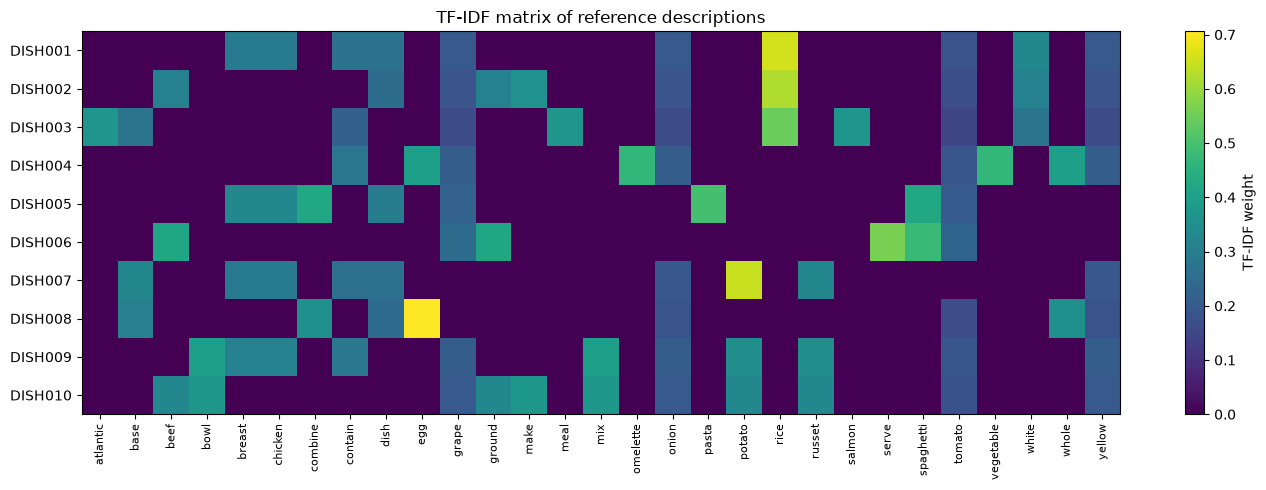

In [23]:
# --------------------------------------------------
# Step 2.2.2 - TF-IDF heatmap
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(X_ref_tfidf.toarray(), aspect="auto", cmap="viridis")
ax.set_xticks(range(len(terms)))
ax.set_xticklabels(terms, rotation=90, fontsize=8)
ax.set_yticks(range(len(dish_labels)))
ax.set_yticklabels(dish_labels)
ax.set_title("TF-IDF matrix of reference descriptions")
plt.colorbar(im, ax=ax, label="TF-IDF weight")
plt.tight_layout()
plt.show()

### 2.2.3 Word and Character n-grams

**Word n-grams (1,2):** adding bigrams such as "ground beef", "chicken breast",
"white rice" restores *local* word order and multi-word food names that
unigrams split apart. The cost is a much larger and sparser vocabulary.

**Character n-grams (3-5, within word boundaries):** represent words by their
sub-strings, so misspellings or variants ("chiken", "tomatoe") still share most
n-grams with the correct word. They add robustness to spelling variation but
still carry no semantic knowledge (fish and salmon share no n-grams).

In [24]:
# --------------------------------------------------
# Step 2.2.3 - Word and character n-grams
# --------------------------------------------------
# Word n-grams (unigrams + bigrams)
tfidf_word = TfidfVectorizer(ngram_range=(1, 2))
X_ref_word = tfidf_word.fit_transform(ref_texts)
X_qry_word = tfidf_word.transform(qry_texts)

# Character n-grams (3 to 5, inside word boundaries)
tfidf_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))
X_ref_char = tfidf_char.fit_transform(ref_texts)
X_qry_char = tfidf_char.transform(qry_texts)

print("Feature counts")
print("Unigram TF-IDF :", len(tfidf.get_feature_names_out()))
print("Word 1-2 grams :", len(tfidf_word.get_feature_names_out()))
print("Char 3-5 grams :", len(tfidf_char.get_feature_names_out()))

bigrams = [f for f in tfidf_word.get_feature_names_out() if " " in f]
print("\nSample bigrams:", bigrams[:15])

# Robustness to spelling errors (unigram vs character n-grams)
typo_tests = [
    ("chiken brest white rise tomatoe onoin", "DISH001"),
    ("salmn with rise and tomatoe",           "DISH003"),
    ("spagetti with chiken",                  "DISH005"),
]

for query, expected in typo_tests:
    print(f"\nQuery: '{query}'  (expected: {expected})")
    for name, vec, X in [("Unigram TF-IDF", tfidf, X_ref_tfidf),
                         ("Char n-grams  ", tfidf_char, X_ref_char)]:
        sims = cosine_similarity(vec.transform([query]), X).ravel()
        best = sims.argmax()
        note = "  <- no vocabulary match" if sims.max() == 0 else ""
        ok = "OK " if dish_labels[best] == expected else "ERR"
        print(f"  {name}: {ok} top-1 = {dish_labels[best]}, score = {sims[best]:.3f}{note}")

Feature counts
Unigram TF-IDF : 29
Word 1-2 grams : 77
Char 3-5 grams : 385

Sample bigrams: ['atlantic salmon', 'base dish', 'base meal', 'beef grape', 'beef russet', 'beef white', 'bowl contain', 'bowl make', 'breast russet', 'breast spaghetti', 'breast white', 'breast yellow', 'chicken breast', 'combine chicken', 'combine whole']

Query: 'chiken brest white rise tomatoe onoin'  (expected: DISH001)
  Unigram TF-IDF: OK  top-1 = DISH001, score = 0.329
  Char n-grams  : OK  top-1 = DISH001, score = 0.487

Query: 'salmn with rise and tomatoe'  (expected: DISH003)
  Unigram TF-IDF: ERR top-1 = DISH001, score = 0.000  <- no vocabulary match
  Char n-grams  : OK  top-1 = DISH003, score = 0.323

Query: 'spagetti with chiken'  (expected: DISH005)
  Unigram TF-IDF: ERR top-1 = DISH001, score = 0.000  <- no vocabulary match
  Char n-grams  : OK  top-1 = DISH005, score = 0.398


### 2.2.4 Word Embeddings (pretrained GloVe)

Training Word2Vec on 10 short descriptions (around 100 tokens) would give
meaningless vectors, so a **pretrained** representation is used: GloVe
(50 dimensions, trained on Wikipedia + Gigaword). A document is represented by
the **average** of its word vectors.

**Captures:** distributional meaning. Words used in similar contexts get similar
vectors (salmon near fish, beef near meat), which BoW/TF-IDF cannot do.

**Fails to capture:**
- *Word order:* averaging discards it.
- *Context:* one vector per word, so "ground" is the same in every sentence.
- *Fine food distinctions:* chicken and beef are very close in embedding space
  (both are meats), which may blur dishes that differ only by the protein.
- *Importance:* averaging weights "rice" and "salmon" equally.

In [25]:
# --------------------------------------------------
# Step 2.2.4a - Load pretrained GloVe (no gensim needed)
# --------------------------------------------------
import gzip
import urllib.request
import numpy as np

GLOVE_URL = ("https://github.com/RaRe-Technologies/gensim-data/releases/download/"
             "glove-wiki-gigaword-50/glove-wiki-gigaword-50.gz")

glove_dir = PROJECT_ROOT / "data" / "external"
glove_dir.mkdir(parents=True, exist_ok=True)
glove_path = glove_dir / "glove-wiki-gigaword-50.gz"

if not glove_path.exists():
    print("Downloading GloVe-50 (~66 MB)...")
    urllib.request.urlretrieve(GLOVE_URL, glove_path)
    print("Saved to:", glove_path)


class GloveVectors:
    """Minimal pretrained-vector container (same interface as gensim KeyedVectors)."""

    def __init__(self, path):
        words, vectors = [], []
        with gzip.open(path, "rt", encoding="utf-8") as f:
            for line in f:
                parts = line.rstrip().split(" ")
                if len(parts) == 2:        # optional "vocab_size dim" header line
                    continue
                words.append(parts[0])
                vectors.append(np.asarray(parts[1:], dtype=np.float32))
        self.vectors = np.vstack(vectors)
        self.key_to_index = {w: i for i, w in enumerate(words)}
        self.vector_size = self.vectors.shape[1]

    def __contains__(self, word):
        return word in self.key_to_index

    def __getitem__(self, word):
        return self.vectors[self.key_to_index[word]]

    def similarity(self, w1, w2):
        a, b = self[w1], self[w2]
        return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))


glove = GloveVectors(glove_path)
print("Loaded GloVe, vocabulary:", len(glove.key_to_index), "dimensions:", glove.vector_size)

Loaded GloVe, vocabulary: 400000 dimensions: 50


In [26]:
# --------------------------------------------------
# Step 2.2.4b - Document embeddings (average of word vectors)
# --------------------------------------------------
dim = glove.vector_size

def doc_vector(tokens):
    vecs = [glove[t] for t in tokens if t in glove]
    return np.mean(vecs, axis=0) if vecs else np.zeros(dim)

# Out-of-vocabulary check
all_tokens = {t for toks in description_df["final_tokens"] for t in toks} | \
             {t for toks in queries_df["final_tokens"] for t in toks}
oov = sorted(t for t in all_tokens if t not in glove)
print("Tokens not in GloVe:", oov if oov else "none")

X_ref_emb = np.vstack(description_df["final_tokens"].apply(doc_vector))
X_qry_emb = np.vstack(queries_df["final_tokens"].apply(doc_vector))
print("Reference embedding matrix:", X_ref_emb.shape)
print("Query embedding matrix:    ", X_qry_emb.shape)

# What embeddings capture: semantic links that BoW/TF-IDF miss
print("\nWord-level cosine similarity (GloVe):")
for w1, w2 in [("fish", "salmon"), ("meat", "beef"), ("ground", "minced"),
               ("chicken", "beef"), ("rice", "pasta"), ("rice", "salmon")]:
    if w1 in glove and w2 in glove:
        print(f"  {w1:8} - {w2:8}: {glove.similarity(w1, w2):.3f}")

Tokens not in GloVe: none
Reference embedding matrix: (10, 50)
Query embedding matrix:     (20, 50)

Word-level cosine similarity (GloVe):
  fish     - salmon  : 0.834
  meat     - beef    : 0.920
  ground   - minced  : 0.337
  chicken  - beef    : 0.833
  rice     - pasta   : 0.490
  rice     - salmon  : 0.540


In [27]:
# --------------------------------------------------
# Step 2.2.5 - Comparison of representations
# --------------------------------------------------
summary = pd.DataFrame([
    {"Representation": "Bag of Words",       "Dimension": X_ref_bow.shape[1],
     "Type": "sparse", "Word order": "no",      "Semantics": "no",  "Term weighting": "no"},
    {"Representation": "TF-IDF",             "Dimension": X_ref_tfidf.shape[1],
     "Type": "sparse", "Word order": "no",      "Semantics": "no",  "Term weighting": "yes"},
    {"Representation": "Word 1-2 grams",     "Dimension": X_ref_word.shape[1],
     "Type": "sparse", "Word order": "local",   "Semantics": "no",  "Term weighting": "yes"},
    {"Representation": "Char 3-5 grams",     "Dimension": X_ref_char.shape[1],
     "Type": "sparse", "Word order": "within words", "Semantics": "no", "Term weighting": "yes"},
    {"Representation": "GloVe average",      "Dimension": X_ref_emb.shape[1],
     "Type": "dense",  "Word order": "no",      "Semantics": "yes", "Term weighting": "no"},
])
display(summary)

# Store all representations for 2.3 (classical retrieval method)
representations = {
    "BoW":        (X_ref_bow,   X_qry_bow),
    "TF-IDF":     (X_ref_tfidf, X_qry_tfidf),
    "Word 1-2":   (X_ref_word,  X_qry_word),
    "Char 3-5":   (X_ref_char,  X_qry_char),
    "GloVe avg":  (X_ref_emb,   X_qry_emb),
}
print("\nRepresentations ready for 2.3:", list(representations))

,Representation,Dimension,Type,Word order,Semantics,Term weighting
0,Bag of Words,29,sparse,no,no,no
1,TF-IDF,29,sparse,no,no,yes
2,Word 1-2 grams,77,sparse,local,no,yes
3,Char 3-5 grams,385,sparse,within words,no,yes
4,GloVe average,50,dense,no,yes,no



Representations ready for 2.3: ['BoW', 'TF-IDF', 'Word 1-2', 'Char 3-5', 'GloVe avg']


## 2.3 Classical Method: Document Retrieval with Vector Similarity

Each query is compared with the 10 reference descriptions using **cosine
similarity**, and the references are ranked. The task is to retrieve the dish
the query was written for (`expected_dish_id`).

No model is trained: the vectorizers are fitted on the reference descriptions
only, so there is no train/test leakage from the queries into the vocabulary.

## 2.4 Evaluation Baseline

**Protocol:** 20 queries (2 per dish), 10 candidate dishes, same queries for
every representation.

**Metrics**
- **Top-1 accuracy:** fraction of queries whose expected dish is ranked first.
- **Top-3 accuracy:** fraction with the expected dish among the first three.
- **MRR (Mean Reciprocal Rank):** average of 1/rank of the expected dish.
  MRR = 1 means always first; a random ranking over 10 dishes gives about 0.29.

**Ties:** ranks are computed pessimistically (a dish with a score equal to the
correct dish counts as ranked above it). A query with all-zero similarities
therefore gets rank 10 instead of a lucky first position.

**Sample size:** with 20 queries, each query is worth 5 percentage points, so
small differences between representations are not statistically meaningful.

In [28]:
# --------------------------------------------------
# Step 2.3 / 2.4 - Retrieval and evaluation
# --------------------------------------------------
expected = queries_df["expected_dish_id"].tolist()
exp_idx = np.array([dish_labels.index(e) for e in expected])
n_q = len(expected)

def evaluate(X_ref, X_qry, tol=1e-9):
    sims = cosine_similarity(X_qry, X_ref)                  # (20, 10)
    true_scores = sims[np.arange(n_q), exp_idx]
    # pessimistic rank: 1 + number of OTHER dishes with score >= correct dish
    ranks = 1 + ((sims >= true_scores[:, None] - tol).sum(axis=1) - 1)
    return sims, ranks

results, all_ranks, all_sims = [], {}, {}
for name, (X_ref, X_qry) in representations.items():
    sims, ranks = evaluate(X_ref, X_qry)
    all_ranks[name], all_sims[name] = ranks, sims
    results.append({
        "Representation": name,
        "Top-1": np.mean(ranks == 1),
        "Top-3": np.mean(ranks <= 3),
        "MRR":   np.mean(1 / ranks),
    })

results_df = pd.DataFrame(results).set_index("Representation")
display(results_df.style.format("{:.3f}"))

# Manual check of MRR for one representation (shows the arithmetic)
r = all_ranks["TF-IDF"]
print("TF-IDF ranks of the correct dish per query:", r.tolist())
print("MRR = (1/20) * sum(1/rank) =", f"{np.mean(1 / r):.3f}")

,Top-1,Top-3,MRR
Representation,,,
BoW,0.850,1.000,0.925
TF-IDF,0.750,1.000,0.875
Word 1-2,0.750,1.000,0.875
Char 3-5,0.800,1.000,0.892
GloVe avg,0.850,1.000,0.925


TF-IDF ranks of the correct dish per query: [1, 2, 2, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1]
MRR = (1/20) * sum(1/rank) = 0.875


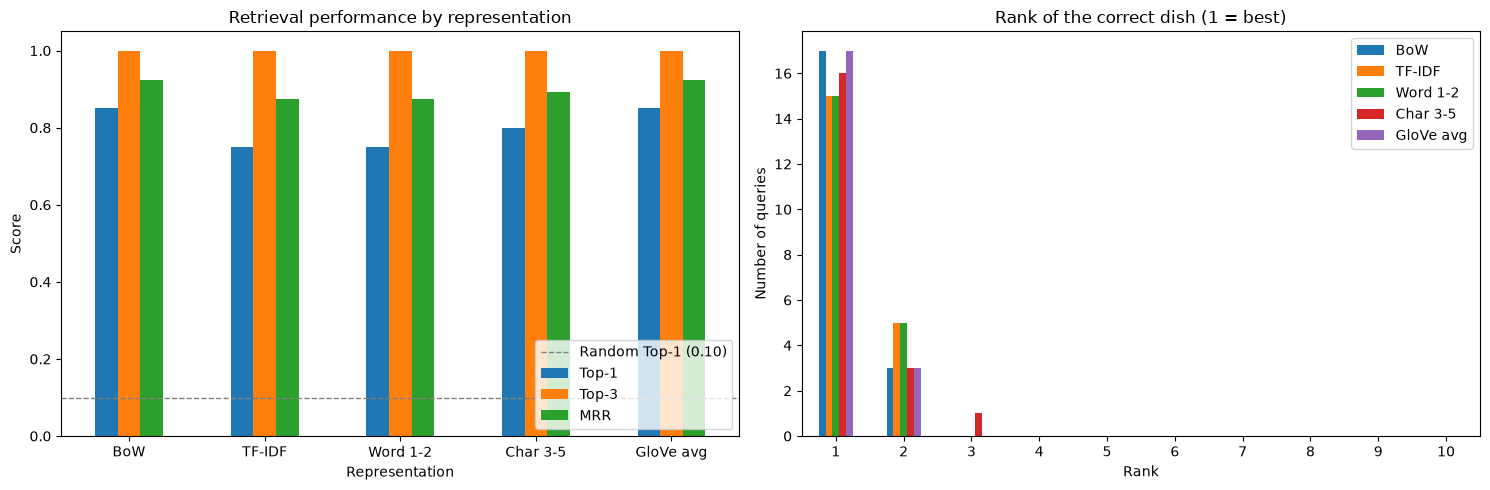

In [29]:
# --------------------------------------------------
# Step 2.4 - Comparison chart and rank distribution
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

results_df.plot(kind="bar", ax=axes[0], rot=0, ylim=(0, 1.05))
axes[0].set_title("Retrieval performance by representation")
axes[0].set_ylabel("Score")
axes[0].axhline(0.1, color="gray", ls="--", lw=1, label="Random Top-1 (0.10)")
axes[0].legend(loc="lower right")

rank_table = pd.DataFrame({
    name: pd.Series(ranks).value_counts().reindex(range(1, 11), fill_value=0)
    for name, ranks in all_ranks.items()
})
rank_table.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Rank of the correct dish (1 = best)")
axes[1].set_xlabel("Rank")
axes[1].set_ylabel("Number of queries")

plt.tight_layout()
plt.show()

In [30]:
# --------------------------------------------------
# Step 2.4 - Error analysis
# --------------------------------------------------
name_of = dict(zip(description_df["dish_id"], description_df["dish_name"]))

for name in representations:
    sims, ranks = all_sims[name], all_ranks[name]
    failed = np.where(ranks > 1)[0]
    print("=" * 70)
    print(f"{name}: {len(failed)} / {n_q} queries not ranked first")
    for i in failed:
        top = sims[i].argmax()
        tie = " (tie / no match)" if (sims[i] == sims[i].max()).sum() > 1 else ""
        print(f"  {queries_df.loc[i, 'query_id']} | {queries_df.loc[i, 'query_text']}")
        print(f"      expected: {name_of[expected[i]]} (rank {ranks[i]}) | "
              f"top: {name_of[dish_labels[top]]}{tie}")

# Queries that fail under EVERY representation
always_failed = np.where(np.all([r > 1 for r in all_ranks.values()], axis=0))[0]
print("\nQueries failed by all representations:",
      queries_df.loc[always_failed, "query_id"].tolist())

BoW: 3 / 20 queries not ranked first
  Q008 | Whole eggs combined with grape tomatoes and yellow onions.
      expected: Vegetable Omelette (rank 2) | top: Tomato and Egg Dish
  Q012 | A pasta meal combining ground meat and grape tomatoes.
      expected: Spaghetti with Ground Beef (rank 2) | top: Chicken Pasta
  Q018 | Chicken breast with russet potatoes and vegetables.
      expected: Chicken and Vegetable Bowl (rank 2) | top: Baked Potato with Chicken
TF-IDF: 5 / 20 queries not ranked first
  Q002 | A meal of rice with chicken, grape tomatoes and yellow onions.
      expected: Chicken with Rice (rank 2) | top: Salmon with Rice
  Q003 | Ground beef served alongside rice, tomatoes and onion.
      expected: Beef with Rice (rank 2) | top: Spaghetti with Ground Beef
  Q008 | Whole eggs combined with grape tomatoes and yellow onions.
      expected: Vegetable Omelette (rank 2) | top: Tomato and Egg Dish
  Q012 | A pasta meal combining ground meat and grape tomatoes.
      expected: Spagh

## 2.5 Conclusion: Baseline and Its Limitations

**Baseline.** Five text representations (BoW, TF-IDF, word 1-2 grams, char
3-5 grams, averaged GloVe-50) were compared on a retrieval task with cosine
similarity: 20 queries, 10 candidate dishes. Top-1 accuracy ranges from 0.75
to 0.85, Top-3 is 1.00 for all, and MRR ranges from 0.875 to 0.925. BoW and
GloVe obtain the highest scores (0.85 / 0.925), TF-IDF and word 1-2 grams the
lowest (0.75 / 0.875).

**Limitations.**
1. **Small evaluation set.** With 20 queries, one query is worth 5 points and
   the 95% interval around 0.85 is roughly +/-0.16, so differences between
   representations are not statistically meaningful. Top-3 is saturated
   because only 10 dishes are candidates.
2. **Templated, non-independent text.** Queries and descriptions were written
   by the same author with shared phrasing. Errors follow template words
   (meal, served, combining) rather than food content, and IDF estimated on 10
   documents rewards these words (e.g. Q002, Q003, Q008).
3. **Lexical gap.** Count-based representations cannot match synonyms or
   hypernyms (meat-beef, fish-salmon): all four failed Q012 ("ground meat").
   GloVe averaging bridges this gap but blurs close categories
   (chicken-beef similarity 0.83).
4. **Near-duplicate dishes and label ambiguity.** Vegetable Omelette and
   Tomato and Egg Dish share almost the same ingredients (Q007, Q008, Q015),
   and the expected dish for Q018 depends on a word ("vegetable") absent from
   its description.
5. **No word order or context.** BoW, TF-IDF and averaged embeddings ignore
   order and give one vector per word; bigrams capture only local order and
   create false bigrams across ingredient boundaries because punctuation was
   removed.
6. **Preprocessing tuned on the evaluation queries** (e.g. minced -> ground),
   which makes the scores slightly optimistic.

**Next steps.** Enlarge the dataset, write independent queries, use a
dev/test split for tuning, report Top-1/Top-3/MRR on the held-out set, and
compare against contextual representations in the following steps.